In [12]:
# 1. Data handling
import pandas as pd
import numpy as np

# 2. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer


# 4. Classification models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline

# 5. Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# 6. Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 7. Cross-validation
from sklearn.model_selection import (
    StratifiedKFold,
    KFold,
    cross_val_score
)

# 8. PCA
from sklearn.decomposition import PCA

# 9. Bagging and Boosting
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from sklearn.ensemble import AdaBoostClassifier

# 10. Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

print("All libraries imported successfully!")

All libraries imported successfully!


   compactness  circularity  distance_circularity  radius_ratio  \
0           95         48.0                  83.0         178.0   
1           91         41.0                  84.0         141.0   
2          104         50.0                 106.0         209.0   
3           93         41.0                  82.0         159.0   
4           85         44.0                  70.0         205.0   

   pr.axis_aspect_ratio  max.length_aspect_ratio  scatter_ratio  \
0                  72.0                       10          162.0   
1                  57.0                        9          149.0   
2                  66.0                       10          207.0   
3                  63.0                        9          144.0   
4                 103.0                       52          149.0   

   elongatedness  pr.axis_rectangularity  max.length_rectangularity  \
0           42.0                    20.0                        159   
1           45.0                    19.0            

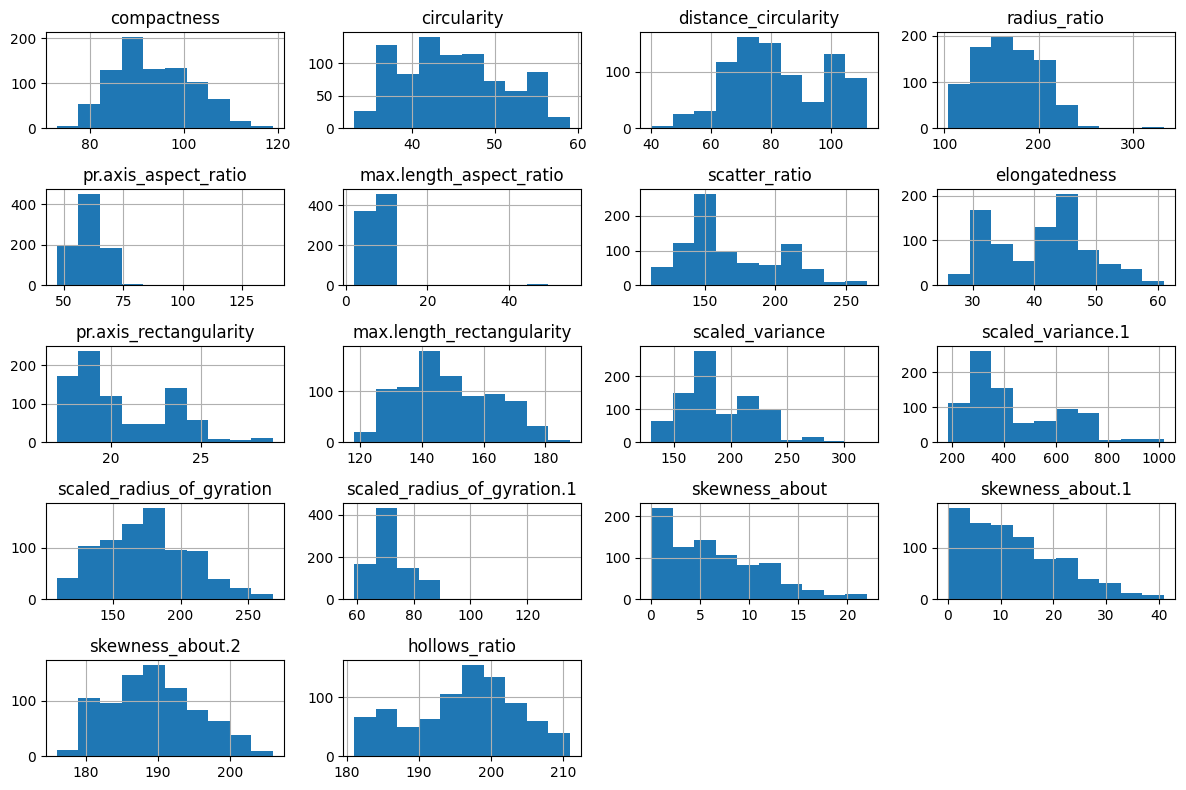

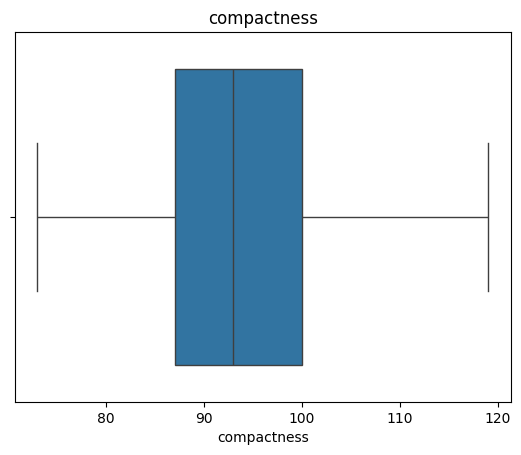

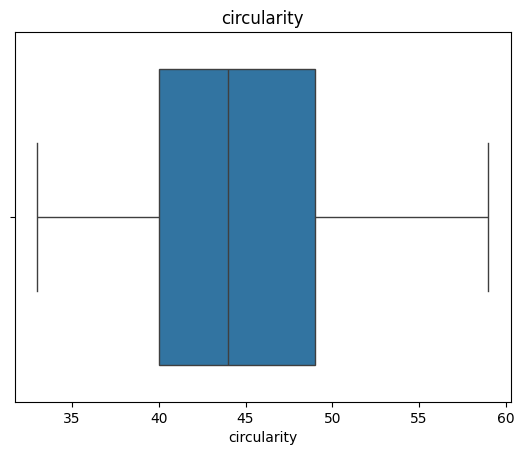

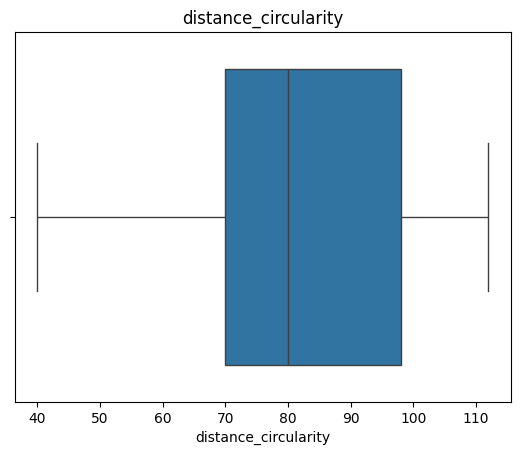

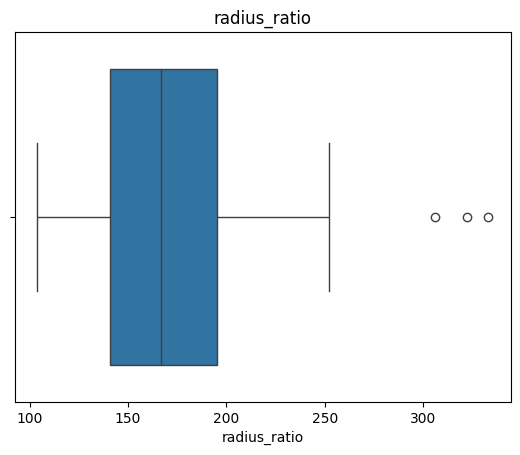

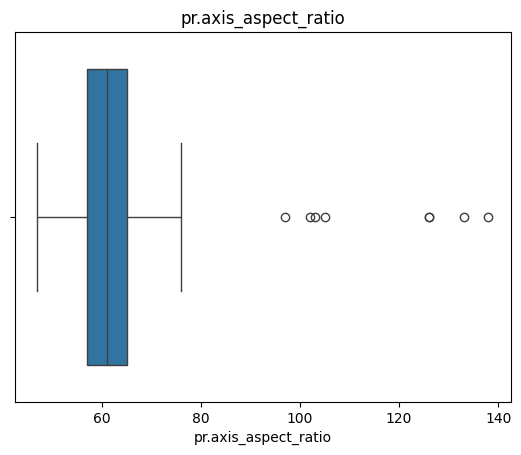

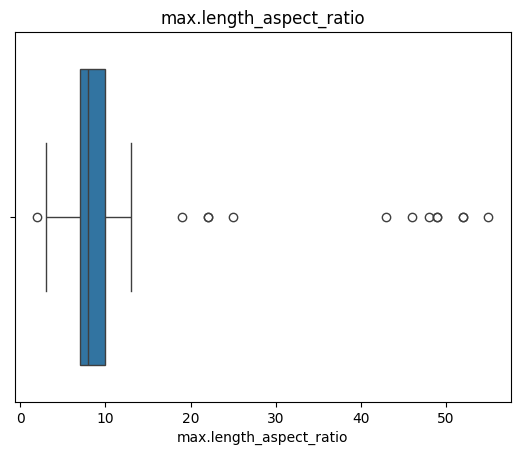

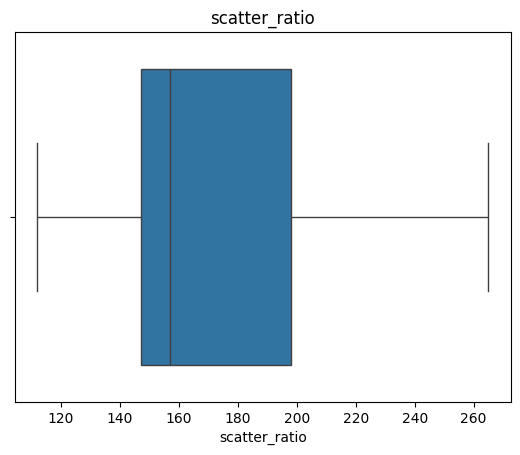

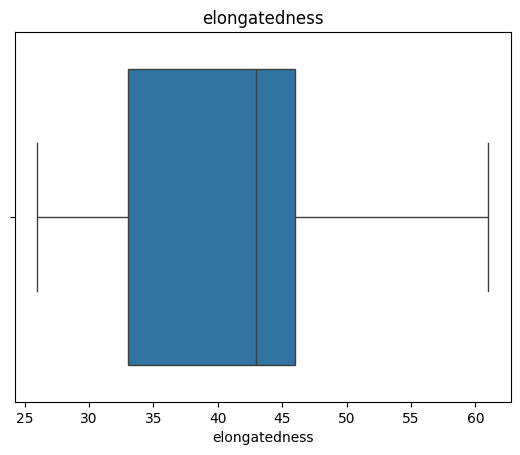

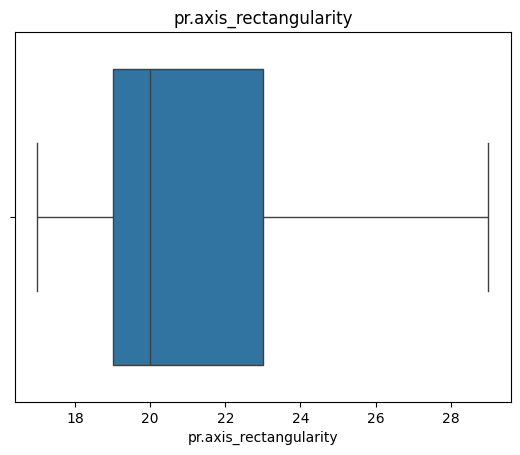

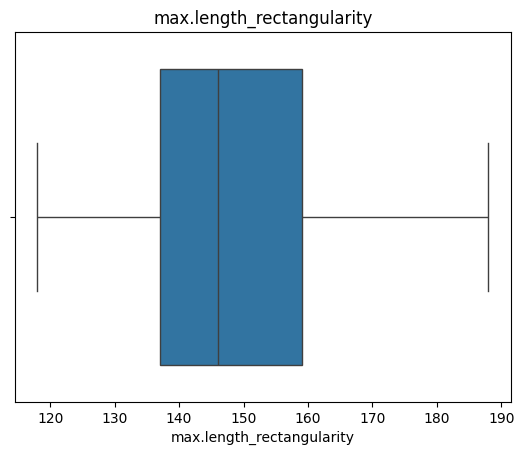

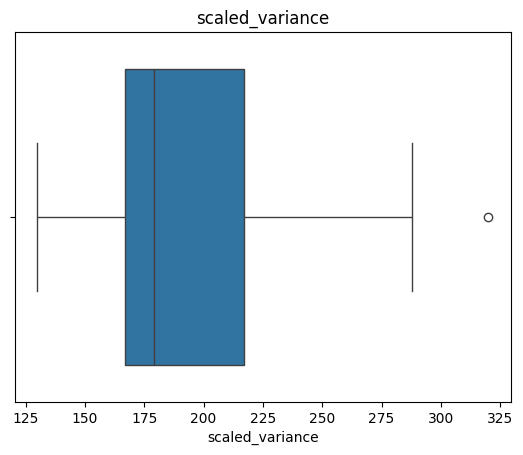

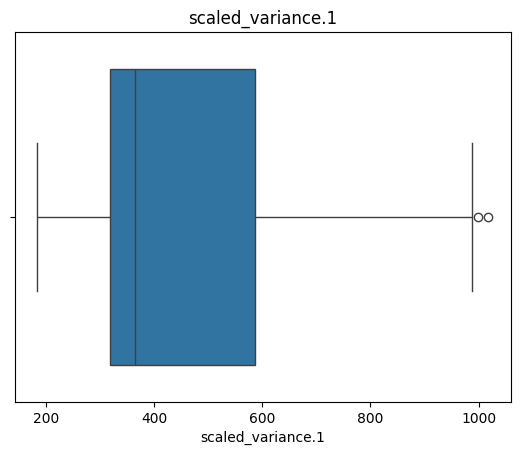

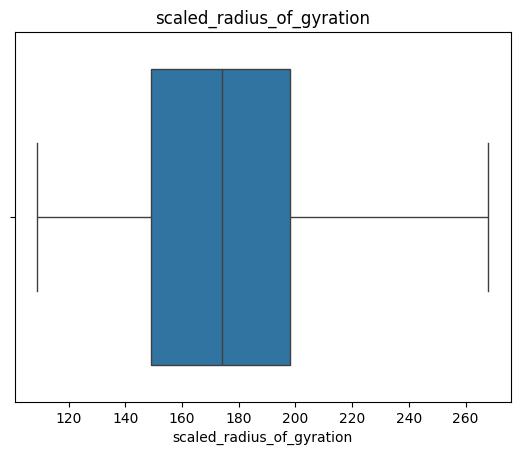

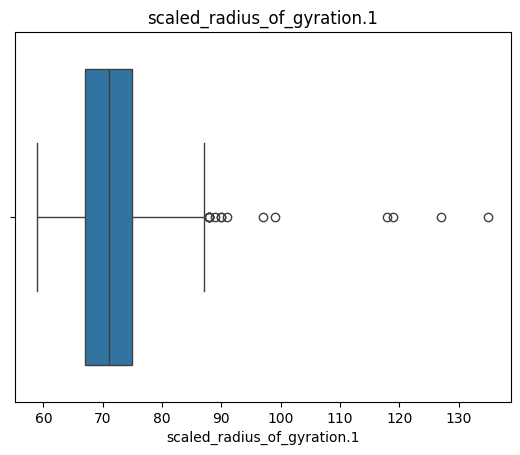

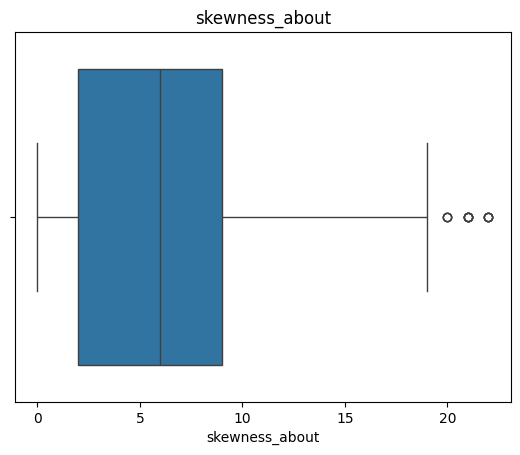

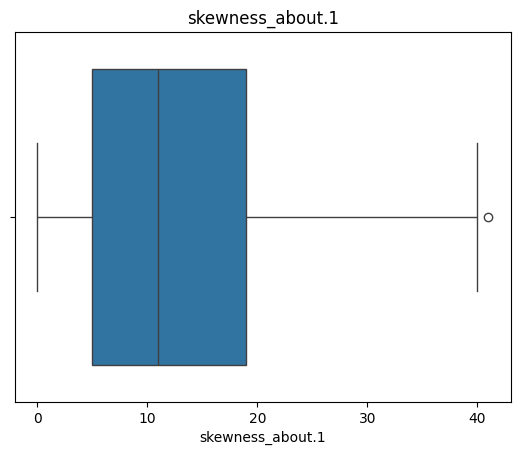

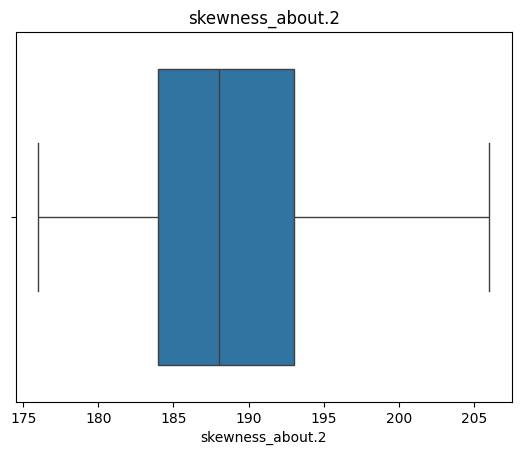

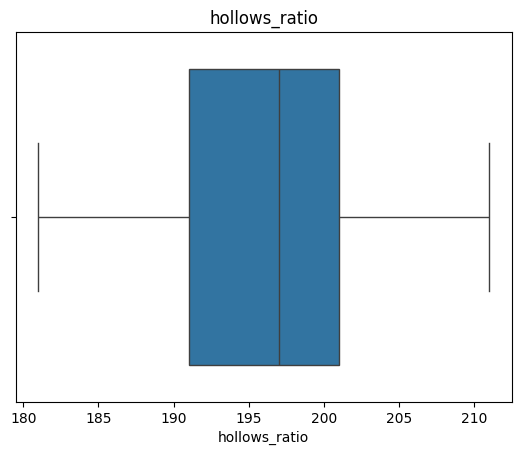

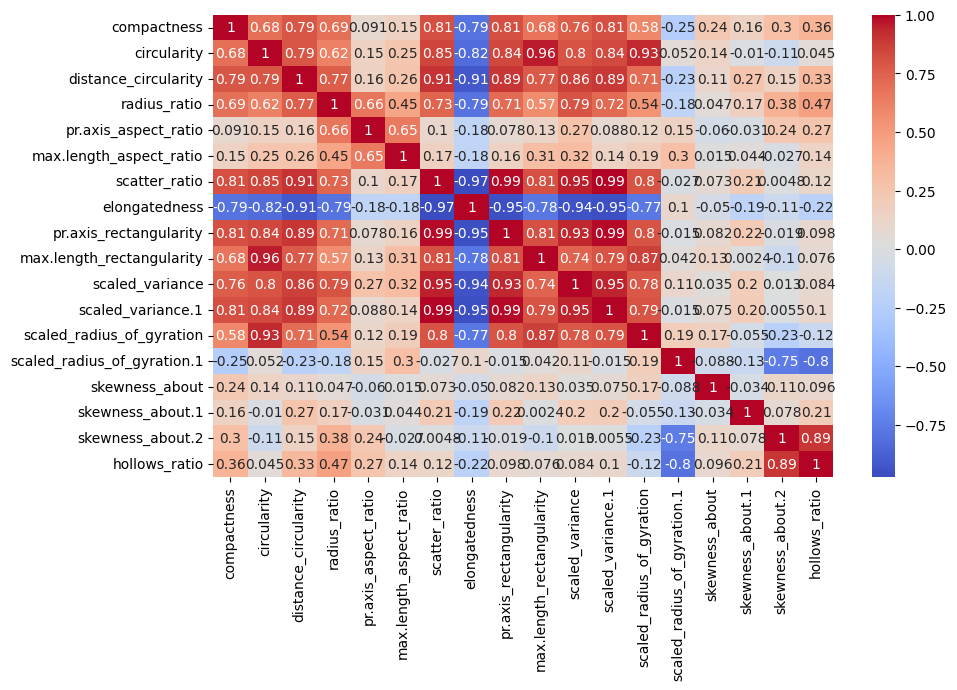

In [13]:
# Load dataset — change filename
df = pd.read_csv("/kaggle/input/datasets/rithikkotha/pca-dataset/pca.csv")

# Inspect dataset
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numeric values
df = df.copy()
num_cols = df.select_dtypes(include=np.number).columns

df[num_cols] = df[num_cols].fillna(
    df[num_cols].median()
)

# Histograms
df[num_cols].hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

# Boxplots
for col in num_cols:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.show()

In [14]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# Identify target column
target_candidates = [
    "target", "HeartDisease", "G3",
    "Type", "Class", "Outcome", "class", "axis"
]

# Normalize column names
column_map = {col.strip().lower(): col for col in df.columns}

target = next(
    (column_map[name.lower()] for name in target_candidates
     if name.lower() in column_map),
    None
)

# Stop if target is not found
if target is None:
    print("Target not detected!")
    print("Available columns:", df.columns.tolist())

else:
    print("Target column:", target)

    # Correlation analysis
    corr = df.select_dtypes(include=np.number).corr()

    if target in corr.columns:
        print("\nCorrelation with target:")
        print(corr[target].sort_values(ascending=False))
    else:
        print("Target is non-numeric; encode it for correlation analysis.")

    # Separate features and target
    X = pd.get_dummies(
        df.drop(columns=[target]), drop_first=True
    )
    y = df[target]

    # Encode target labels
    if y.dtype == "object" or isinstance(y.dtype, pd.CategoricalDtype):
        y = LabelEncoder().fit_transform(y)

    # Handle missing values
    X = X.fillna(X.median()).fillna(0)

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print("\nTraining:", X_train.shape)
    print("Testing:", X_test.shape)

    # Feature scaling
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Train KNN model
    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Evaluation
    print("\nAccuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    ))
    print("Recall:", recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    ))
    print("F1-score:", f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    ))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Target column: class
Target is non-numeric; encode it for correlation analysis.

Training: (676, 18)
Testing: (169, 18)

Accuracy: 0.9171597633136095
Precision: 0.9186098454391137
Recall: 0.9171597633136095
F1-score: 0.9176241915508464
Confusion Matrix:
 [[41  3  0]
 [ 1 79  6]
 [ 0  4 35]]


In [15]:
# 8. KNN model
knn = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)

print("\nKNN Results")
print("Accuracy:", accuracy_score(y_test, pred_knn))
print("Precision:", precision_score(y_test, pred_knn, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred_knn, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, pred_knn, average="weighted", zero_division=0))
print(confusion_matrix(y_test, pred_knn))

# 9. SVM with different kernels
for kernel in ["linear", "rbf", "poly"]:
    svm = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(kernel=kernel)
    )
    svm.fit(X_train, y_train)
    pred = svm.predict(X_test)

    print("\nSVM Kernel:", kernel)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred, average="weighted", zero_division=0))


KNN Results
Accuracy: 0.9171597633136095
Precision: 0.9186098454391137
Recall: 0.9171597633136095
F1 Score: 0.9176241915508464
[[41  3  0]
 [ 1 79  6]
 [ 0  4 35]]

SVM Kernel: linear
Accuracy: 0.9349112426035503
F1 Score: 0.9357436086181026

SVM Kernel: rbf
Accuracy: 0.9704142011834319
F1 Score: 0.9704807057946936

SVM Kernel: poly
Accuracy: 0.834319526627219
F1 Score: 0.8303922797849923


In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(knn, X, y, cv=cv, scoring="accuracy")
print("\nCross-validation scores:", scores)
print("Mean CV Accuracy:", scores.mean())


Cross-validation scores: [0.89349112 0.9112426  0.92307692 0.93491124 0.91715976]
Mean CV Accuracy: 0.9159763313609467


Question 2

In [17]:
lr = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, pred_lr))
print("MSE:", mean_squared_error(y_test, pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("R2 Score:", r2_score(y_test, pred_lr))
dt = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeRegressor(max_depth=5, random_state=42)
)

dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)

print("Decision Tree Regression")
print("MAE:", mean_absolute_error(y_test, pred_dt))
print("MSE:", mean_squared_error(y_test, pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_dt)))
print("R2 Score:", r2_score(y_test, pred_dt))

Linear Regression
MAE: 0.3552296156655485
MSE: 0.19477205209432122
RMSE: 0.44132986766626303
R2 Score: 0.6027078574585124
Decision Tree Regression
MAE: 0.1361511176599934
MSE: 0.10604109182050762
RMSE: 0.3256395120689558
R2 Score: 0.7836994983941209


In [18]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [
        mean_absolute_error(y_test, pred_lr),
        mean_absolute_error(y_test, pred_dt)
    ],
    "MSE": [
        mean_squared_error(y_test, pred_lr),
        mean_squared_error(y_test, pred_dt)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_lr)),
        np.sqrt(mean_squared_error(y_test, pred_dt))
    ],
    "R2 Score": [
        r2_score(y_test, pred_lr),
        r2_score(y_test, pred_dt)
    ]
})

print(results)

               Model       MAE       MSE     RMSE  R2 Score
0  Linear Regression  0.355230  0.194772  0.44133  0.602708
1      Decision Tree  0.136151  0.106041  0.32564  0.783699


In [19]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    lr, X, y,
    cv=cv,
    scoring="r2"
)

print("R2 scores:", scores)
print("Mean R2:", scores.mean())

R2 scores: [0.62164693 0.6762793  0.66079388 0.59770495 0.64661163]
Mean R2: 0.640607339540883


In [20]:
# Preprocess the data before Bagging
imputer = SimpleImputer(strategy="median")

X_train_clean = imputer.fit_transform(X_train)
X_test_clean = imputer.transform(X_test)

bag = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=5),
    n_estimators=50,
    random_state=42
)

bag.fit(X_train_clean, y_train)
pred_bag = bag.predict(X_test_clean)

print("Bagging Regression")
print("MAE:", mean_absolute_error(y_test, pred_bag))
print("MSE:", mean_squared_error(y_test, pred_bag))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_bag)))
print("R2 Score:", r2_score(y_test, pred_bag))

Bagging Regression
MAE: 0.1419606708735808
MSE: 0.05804745505859098
RMSE: 0.24093039463419924
R2 Score: 0.8815959602964992


Question 3


In [21]:
lr = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, pred_lr))
print("Precision:", precision_score(y_test, pred_lr, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred_lr, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, pred_lr, average="weighted", zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred_lr))
print(classification_report(y_test, pred_lr, zero_division=0))
mlp = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(100,),
        max_iter=1000,
        random_state=42
    )
)

mlp.fit(X_train, y_train)
pred_mlp = mlp.predict(X_test)

print("MLP Classifier")
print("Accuracy:", accuracy_score(y_test, pred_mlp))
print("Precision:", precision_score(y_test, pred_mlp, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred_mlp, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, pred_mlp, average="weighted", zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred_mlp))

Logistic Regression
Accuracy: 0.9349112426035503
Precision: 0.9376027409578964
Recall: 0.9349112426035503
F1 Score: 0.9350725107479937
Confusion Matrix:
 [[42  1  1]
 [ 5 78  3]
 [ 0  1 38]]
              precision    recall  f1-score   support

           0       0.89      0.95      0.92        44
           1       0.97      0.91      0.94        86
           2       0.90      0.97      0.94        39

    accuracy                           0.93       169
   macro avg       0.92      0.95      0.93       169
weighted avg       0.94      0.93      0.94       169

MLP Classifier
Accuracy: 0.9763313609467456
Precision: 0.9766178266178265
Recall: 0.9763313609467456
F1 Score: 0.9763377272635237
Confusion Matrix:
 [[44  0  0]
 [ 1 83  2]
 [ 0  1 38]]


In [22]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "MLP"],
    "Accuracy": [
        accuracy_score(y_test, pred_lr),
        accuracy_score(y_test, pred_mlp)
    ],
    "Precision": [
        precision_score(y_test, pred_lr, average="weighted", zero_division=0),
        precision_score(y_test, pred_mlp, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_lr, average="weighted", zero_division=0),
        recall_score(y_test, pred_mlp, average="weighted", zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, pred_lr, average="weighted", zero_division=0),
        f1_score(y_test, pred_mlp, average="weighted", zero_division=0)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.934911   0.937603  0.934911  0.935073
1                  MLP  0.976331   0.976618  0.976331  0.976338


In [23]:
#PCA retaining 95% variance
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("PCA features:", X_train_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())

lr_pca = LogisticRegression(max_iter=2000)
lr_pca.fit(X_train_pca, y_train)

pred_pca = lr_pca.predict(X_test_pca)

print("PCA Logistic Regression Accuracy:",
      accuracy_score(y_test, pred_pca))

Original features: 18
PCA features: 7
Explained variance: 0.9619300406670134
PCA Logistic Regression Accuracy: 0.7633136094674556


In [24]:
# Preprocess separately before bagging
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_clean = scaler.fit_transform(imputer.fit_transform(X_train))
X_test_clean = scaler.transform(imputer.transform(X_test))

bag = BaggingClassifier(
    estimator=LogisticRegression(max_iter=2000),
    n_estimators=10,
    random_state=42
)

bag.fit(X_train_clean, y_train)
pred_bag = bag.predict(X_test_clean)

print("Bagging Logistic Regression")
print("Accuracy:", accuracy_score(y_test, pred_bag))
print("Precision:", precision_score(y_test, pred_bag, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred_bag, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, pred_bag, average="weighted", zero_division=0))
print(classification_report(y_test, pred_bag, zero_division=0))

Bagging Logistic Regression
Accuracy: 0.9289940828402367
Precision: 0.932594669206159
Recall: 0.9289940828402367
F1 Score: 0.9291903686552515
              precision    recall  f1-score   support

           0       0.88      0.95      0.91        44
           1       0.97      0.90      0.93        86
           2       0.90      0.97      0.94        39

    accuracy                           0.93       169
   macro avg       0.92      0.94      0.93       169
weighted avg       0.93      0.93      0.93       169



In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    lr, X, y,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", scores)
print("Mean accuracy:", scores.mean())

Cross-validation scores: [0.95857988 0.92307692 0.91715976 0.95857988 0.96449704]
Mean accuracy: 0.9443786982248522


Question 4

In [26]:
#knn 
knn = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, pred_knn))
print("Precision:", precision_score(y_test, pred_knn, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred_knn, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, pred_knn, average="weighted", zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred_knn))
print(classification_report(y_test, pred_knn, zero_division=0))

#random forest
rf = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42
    )
)

rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, pred_rf))
print("Precision:", precision_score(y_test, pred_rf, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred_rf, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, pred_rf, average="weighted", zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred_rf))
print(classification_report(y_test, pred_rf, zero_division=0))

KNN Accuracy: 0.9171597633136095
Precision: 0.9186098454391137
Recall: 0.9171597633136095
F1 Score: 0.9176241915508464
Confusion Matrix:
 [[41  3  0]
 [ 1 79  6]
 [ 0  4 35]]
              precision    recall  f1-score   support

           0       0.98      0.93      0.95        44
           1       0.92      0.92      0.92        86
           2       0.85      0.90      0.88        39

    accuracy                           0.92       169
   macro avg       0.92      0.92      0.92       169
weighted avg       0.92      0.92      0.92       169

Random Forest Accuracy: 0.9112426035502958
Precision: 0.9126505436427398
Recall: 0.9112426035502958
F1 Score: 0.9111192473698231
Confusion Matrix:
 [[40  4  0]
 [ 6 76  4]
 [ 0  1 38]]
              precision    recall  f1-score   support

           0       0.87      0.91      0.89        44
           1       0.94      0.88      0.91        86
           2       0.90      0.97      0.94        39

    accuracy                           0.

In [27]:
#compare knn and random forest
results = pd.DataFrame({
    "Model": ["KNN", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, pred_knn),
        accuracy_score(y_test, pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, pred_knn, average="weighted", zero_division=0),
        f1_score(y_test, pred_rf, average="weighted", zero_division=0)
    ]
})

print(results)

           Model  Accuracy  F1 Score
0            KNN  0.917160  0.917624
1  Random Forest  0.911243  0.911119


In [28]:
#PCA retaining 95% variance
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("PCA features:", X_train_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())

knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_pca, y_train)

pred_pca = knn_pca.predict(X_test_pca)

print("KNN with PCA Accuracy:", accuracy_score(y_test, pred_pca))

Original features: 18
PCA features: 7
Explained variance: 0.9619300406670134
KNN with PCA Accuracy: 0.8875739644970414


In [29]:
#Bagging with knn

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_clean = scaler.fit_transform(imputer.fit_transform(X_train))
X_test_clean = scaler.transform(imputer.transform(X_test))

bag = BaggingClassifier(
    estimator=KNeighborsClassifier(n_neighbors=5),
    n_estimators=10,
    random_state=42
)

bag.fit(X_train_clean, y_train)
pred_bag = bag.predict(X_test_clean)

print("Bagging KNN Accuracy:", accuracy_score(y_test, pred_bag))
print("Precision:", precision_score(y_test, pred_bag, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, pred_bag, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, pred_bag, average="weighted", zero_division=0))
print(classification_report(y_test, pred_bag, zero_division=0))

Bagging KNN Accuracy: 0.9289940828402367
Precision: 0.9295961194440623
Recall: 0.9289940828402367
F1 Score: 0.9292291162485569
              precision    recall  f1-score   support

           0       0.98      0.95      0.97        44
           1       0.93      0.93      0.93        86
           2       0.88      0.90      0.89        39

    accuracy                           0.93       169
   macro avg       0.93      0.93      0.93       169
weighted avg       0.93      0.93      0.93       169



In [30]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    knn, X, y,
    cv=cv,
    scoring="accuracy"
)

print("CV scores:", scores)
print("Mean CV accuracy:", scores.mean())

CV scores: [0.89349112 0.9112426  0.92307692 0.93491124 0.91715976]
Mean CV accuracy: 0.9159763313609467
